In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('comments.csv')

In [3]:
# Inspect class distribution
print("\nDataset Class Distribution:")
print(df['cyberbullying_type'].value_counts())



Dataset Class Distribution:
cyberbullying_type
not_cyberbullying      775
ethnicity              209
gender                 205
other_cyberbullying    205
religion               204
age                    203
Name: count, dtype: int64


In [4]:
# 2. Define features (X) and target labels (y)
X = df['tweet_text'].astype(str)
y = df['cyberbullying_type']

In [5]:
# 3. Train-Test Split (Stratified to maintain class proportions)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print(f"\nTraining set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")


Training set size: 1440 samples
Testing set size: 361 samples


In [6]:
# 4. Build a Machine Learning Pipeline
# TF-IDF Vectorizer + Logistic Regression with class balancing
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=15000, 
        ngram_range=(1, 2), 
        stop_words='english'
    )),
    ('clf', LogisticRegression(
        class_weight='balanced', 
        max_iter=1000, 
        C=2.0, 
        random_state=42
    ))
])

print("\n2. Training the model...")
pipeline.fit(X_train, y_train)

print("\n3. Evaluating model performance on test set...")
y_pred = pipeline.predict(X_test)

# Print detailed metrics report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


2. Training the model...

3. Evaluating model performance on test set...

Classification Report:
                     precision    recall  f1-score   support

                age       0.97      0.90      0.94        41
          ethnicity       0.78      0.86      0.82        42
             gender       0.89      0.80      0.85        41
  not_cyberbullying       0.96      0.99      0.98       155
other_cyberbullying       0.85      0.83      0.84        41
           religion       0.95      0.93      0.94        41

           accuracy                           0.92       361
          macro avg       0.90      0.89      0.89       361
       weighted avg       0.92      0.92      0.92       361



In [7]:




# 4. Optional: Quick text prediction test
print("\n4. Running quick prediction tests on custom strings:")
test_samples = [
    "boomers need to step down from office already",
    "can someone help me configure a docker container?",
    "go back to your country nobody wants u here",
    "your outfit looks like a trash bag",
    "women shouldn't work in engineering fields"
]

predictions = pipeline.predict(test_samples)
for text, pred in zip(test_samples, predictions):
    print(f"Text: '{text}' --> Predicted Class: [{pred}]")


4. Running quick prediction tests on custom strings:
Text: 'boomers need to step down from office already' --> Predicted Class: [age]
Text: 'can someone help me configure a docker container?' --> Predicted Class: [not_cyberbullying]
Text: 'go back to your country nobody wants u here' --> Predicted Class: [ethnicity]
Text: 'your outfit looks like a trash bag' --> Predicted Class: [other_cyberbullying]
Text: 'women shouldn't work in engineering fields' --> Predicted Class: [gender]


share of 'bullying' (5 classes together): 0.858
accuracy of a model that ALWAYS says 'bullying': 0.858

no class weights                   acc=0.904 balAcc=0.729 | NOT-bully P=0.751 R=0.484 F1=0.589 | AUC=0.936
class_weight='balanced'            acc=0.889 balAcc=0.831 | NOT-bully P=0.586 R=0.750 F1=0.658 | AUC=0.936
balanced, WITHOUT 'other' class    acc=0.937 balAcc=0.911 | NOT-bully P=0.776 R=0.871 F1=0.821 | AUC=0.975


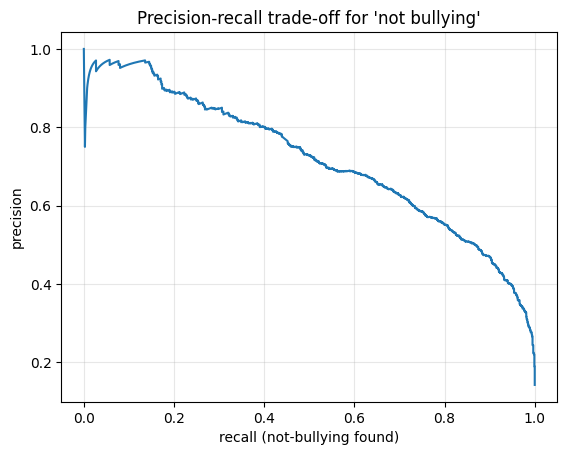

best threshold on P(not bully) = 0.54 -> P=0.614 R=0.722 F1=0.663
words  0-  4: n=  204  6-class acc=0.578
words  4-  7: n=  448  6-class acc=0.696
words  7- 13: n= 1380  6-class acc=0.776
words 13- 26: n= 3508  6-class acc=0.853
words 26-999: n= 3041  6-class acc=0.988

type among bullying (5 classes): acc=0.952 macroF1=0.948
wrote gold_to_label.csv


In [1]:
import pandas as pd, numpy as np, re, warnings
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, precision_recall_curve, f1_score)

# ---------- data (same cleaning as before; hashtags optional) ----------
def clean(t, drop_hashtags=False):
    t = t.lower(); t = re.sub(r"http\S+|www\S+", " ", t); t = re.sub(r"@\w+", " ", t); t = re.sub(r"^rt ", " ", t) ; t = re.sub(r"^mkr ", " ", t)
    if drop_hashtags: t = re.sub(r"#\w+", " ", t)
    return " ".join(re.sub(r"[^a-z\s']", " ", t).split())

df = pd.read_csv("cyberbullying_tweets.csv").drop_duplicates()
df = df.drop_duplicates("tweet_text", keep=False).reset_index(drop=True)
df["clean"] = df.tweet_text.map(clean)
df = df.drop_duplicates("clean", keep=False).reset_index(drop=True)
y = df.cyberbullying_type
is_bully = (y != "not_cyberbullying").astype(int)            # 1 = bullying, 0 = not bullying
tr, te = train_test_split(np.arange(len(df)), test_size=0.2, stratify=y, random_state=42)

print("share of 'bullying' (5 classes together): %.3f" % is_bully.mean())
print("accuracy of a model that ALWAYS says 'bullying': %.3f\n" % is_bully[te].mean())

# ---------- Task 1: bullying vs not bullying ----------
def binary_experiment(name, rows_tr, rows_te, class_weight):
    vec = TfidfVectorizer(min_df=3, ngram_range=(1, 2), sublinear_tf=True)
    A = vec.fit_transform(df.clean[rows_tr])
    m = LogisticRegression(max_iter=2000, C=5, class_weight=class_weight).fit(A, is_bully[rows_tr])
    pr = m.predict_proba(vec.transform(df.clean[rows_te]))[:, 1]; yt = is_bully[rows_te].values; p = (pr > 0.5).astype(int)
    P, R, F, _ = precision_recall_fscore_support(yt, p, labels=[0], zero_division=0)   # label 0 = minority class
    print(f"{name:34s} acc={accuracy_score(yt,p):.3f} balAcc={balanced_accuracy_score(yt,p):.3f} "
          f"| NOT-bully P={P[0]:.3f} R={R[0]:.3f} F1={F[0]:.3f} | AUC={roc_auc_score(yt,pr):.3f}")
    return yt, pr

binary_experiment("no class weights", tr, te, None)
yt, pr = binary_experiment("class_weight='balanced'", tr, te, "balanced")
keep = (y != "other_cyberbullying").values
binary_experiment("balanced, WITHOUT 'other' class", [i for i in tr if keep[i]], [i for i in te if keep[i]], "balanced")

# ---------- precision-recall curve for the minority class ----------
P, R, T = precision_recall_curve(1 - yt, 1 - pr)             # 'not bullying' treated as the positive class
plt.plot(R, P); plt.xlabel("recall (not-bullying found)"); plt.ylabel("precision"); plt.grid(alpha=.3)
plt.title("Precision-recall trade-off for 'not bullying'"); plt.show()
f1s = 2 * P * R / (P + R + 1e-9); b = f1s[:-1].argmax()
print("best threshold on P(not bully) = %.2f -> P=%.3f R=%.3f F1=%.3f" % (T[b], P[b], R[b], f1s[b]))

# ---------- accuracy by tweet length ----------
vec = TfidfVectorizer(min_df=3, ngram_range=(1, 2), sublinear_tf=True); A = vec.fit_transform(df.clean[tr])
lr = LogisticRegression(max_iter=2000, C=5).fit(A, y[tr]); p6 = lr.predict(vec.transform(df.clean[te]))
nw = df.clean[te].str.split().map(len).values
for lo, hi in [(0, 4), (4, 7), (7, 13), (13, 26), (26, 999)]:
    k = (nw >= lo) & (nw < hi); print(f"words {lo:2d}-{hi:3d}: n={k.sum():5d}  6-class acc={accuracy_score(y[te][k], p6[k]):.3f}")

# ---------- Task 2: which TYPE (only bullying tweets) ----------
btr = [i for i in tr if is_bully[i] == 1]; bte = [i for i in te if is_bully[i] == 1]
v2 = TfidfVectorizer(min_df=3, ngram_range=(1, 2), sublinear_tf=True)
m2 = LogisticRegression(max_iter=2000, C=5).fit(v2.fit_transform(df.clean[btr]), y[btr])
p2 = m2.predict(v2.transform(df.clean[bte]))
print("\ntype among bullying (5 classes): acc=%.3f macroF1=%.3f" % (accuracy_score(y[bte], p2), f1_score(y[bte], p2, average="macro")))

# ---------- GOLD SET: label by hand ----------
gold = df.iloc[te].sample(200, random_state=0)[["tweet_text", "cyberbullying_type"]].copy()
gold["my_label"] = ""   # fill with: bullying / not_bullying  (does THIS tweet attack or harass someone?)
gold["notes"] = ""
gold.to_csv("gold_to_label.csv", index=True); print("wrote gold_to_label.csv")

In [4]:
import pandas as pd, numpy as np, re, os, warnings, joblib
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

KAGGLE, SYNTH = "cyberbullying_tweets.csv", "comments.csv"
HARDNEG = "hard_negatives.csv"      
GOLD    = "gold_to_label.csv"      

def clean(t):
    t = str(t).lower()
    t = re.sub(r"http\S+|www\S+", " ", t); t = re.sub(r"@\w+", " ", t); t = re.sub(r"^mkr", " ", t); t = re.sub(r"^rt ", " ", t)
    t = re.sub(r"#", " ", t)                      # keep the hashtag WORD, drop the symbol
    return " ".join(re.sub(r"[^a-z\s']", " ", t).split())   # keeps 'not', "n't" etc. (no stopword removal)

def load(path):
    d = pd.read_csv(path)[["tweet_text", "cyberbullying_type"]].dropna()
    d = d.drop_duplicates("tweet_text", keep=False)
    d["clean"] = d.tweet_text.map(clean)
    return d.drop_duplicates("clean", keep=False).reset_index(drop=True)

def split(d): return train_test_split(d, test_size=0.2, stratify=d.cyberbullying_type, random_state=42)

sets = {"Kaggle": load(KAGGLE), "Gemini": load(SYNTH) , "HardNeg" : load(HARDNEG)}

parts = {k: split(v) if len(v) > 50 else (v, v.iloc[:0]) for k, v in sets.items()}
train = {k: p[0] for k, p in parts.items()}; test = {k: p[1] for k, p in parts.items() if len(p[1])}
g = load(GOLD); test["GOLD (real, hand-labelled)"] = g

def make(): return Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=3000, C=5, class_weight="balanced"))])

models = {"Kaggle only": ["Kaggle"], "Gemini only": ["Gemini"], "COMBINED": list(train)}
fitted = {}
rows = []
SMALL_SET_WEIGHT = 10   # Gemini / hard-negative rows are few but clean -> count each as 10 rows (tested: 1,5,10,20,40)
for name, srcs in models.items():
    tr = pd.concat([train[s].assign(src=s) for s in srcs])
    w = np.where(tr.src == "Kaggle", 1.0, SMALL_SET_WEIGHT)
    m = make(); m.fit(tr.clean, tr.cyberbullying_type, clf__sample_weight=w); fitted[name] = m
    for tname, te in test.items():
        p = m.predict(te.clean)
        rows.append(dict(model=name, tested_on=tname, n=len(te), acc=round(accuracy_score(te.cyberbullying_type, p), 3),
                         macro_f1=round(f1_score(te.cyberbullying_type, p, average="macro"), 3)))
R = pd.DataFrame(rows)
print("=== every model on every test set (the cross-dataset table) ===")
print(R.pivot(index="model", columns="tested_on", values="acc").to_string())

final = fitted["COMBINED"]
for tname, te in test.items():
    p = final.predict(te.clean); print(f"\n--- COMBINED model on {tname} ---"); print(classification_report(te.cyberbullying_type, p, digits=3, zero_division=0))
te = test["Kaggle"]; ConfusionMatrixDisplay.from_predictions(te.cyberbullying_type, final.predict(te.clean), xticks_rotation=45, cmap="Blues")
plt.tight_layout(); plt.savefig("confusion_kaggle.png", dpi=110); plt.close()
joblib.dump(final, "model2.joblib"); print("\nsaved model.joblib")

# ---- explanation: which words pushed the model toward the predicted class? ----
def predict_explain(text, k=5):
    tf, clf = final.named_steps["tfidf"], final.named_steps["clf"]
    x = tf.transform([clean(text)]); idx = x.nonzero()[1]; vocab = tf.get_feature_names_out()
    proba = clf.predict_proba(x)[0]; order = proba.argsort()[::-1]; top = clf.classes_[order[0]]
    contrib = x[0, idx].toarray().ravel() * clf.coef_[order[0]][idx]; best = np.argsort(contrib)[::-1][:k]
    sure = proba[order[0]] >= 0.6 and len(idx) >= 3     # not-sure rule: low confidence or <3 known words
    return {"verdict": top if sure else "UNSURE (" + top + "?)", "prediction": top, "confidence": round(float(proba[order[0]]), 3),
            "runner_up": (clf.classes_[order[1]], round(float(proba[order[1]]), 3)),
            "key_words": [(vocab[idx[j]], round(float(contrib[j]), 2)) for j in best if contrib[j] > 0],
            "words_seen_by_model": len(idx)}

if __name__ == "__main__":
    for t in ["boomers need to step down from office already", "can someone help me configure a docker container?",
              "go back to your country nobody wants u here", "my muslim friend is the kindest person i know",
              "women shouldn't work in engineering fields", "school :-/"]:
        print(t, "->", predict_explain(t))

=== every model on every test set (the cross-dataset table) ===
tested_on    GOLD (real, hand-labelled)  Gemini  HardNeg  Kaggle
model                                                           
COMBINED                          0.925   0.947    0.957   0.866
Gemini only                       0.265   0.967    0.741   0.252
Kaggle only                       0.935   0.381    0.446   0.869

--- COMBINED model on Kaggle ---
                     precision    recall  f1-score   support

                age      0.955     0.971     0.963      1582
          ethnicity      0.979     0.979     0.979      1551
             gender      0.907     0.847     0.876      1468
  not_cyberbullying      0.656     0.644     0.650      1220
other_cyberbullying      0.665     0.705     0.684      1165
           religion      0.942     0.956     0.949      1588

           accuracy                          0.866      8574
          macro avg      0.851     0.850     0.850      8574
       weighted avg      0